# Phase 1 Preprocessing Sanity Check
This notebook demonstrates loading raw EEG data for subject **S001**, applying Stage 1 preprocessing (bandpass, ICA, autoreject), comparing raw vs. preprocessed epoch signals, and inspecting per-class trial counts and AutoReject diagnostics.

In [1]:
import sys
from pathlib import Path
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import yaml
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import mne
from autoreject import AutoReject
from src.data.loader import load_subject_raw_with_events
from src.data.preprocessing import Preprocessor
from src.data.events import build_run_aware_events

In [2]:
with open(project_root / "config" / "phase1_config.yaml", "r") as f:
    config = yaml.safe_load(f)

config["subject_id"] = "S001"
print("Loading raw data for subject S001 (with run-aware events)...")
raw, run_files, events, event_id = load_subject_raw_with_events("S001")
print(f"Successfully loaded {len(run_files)} run files.")
print(f"Run-aware events: {len(events)} trials, classes: {event_id}")

Loading raw data for subject S001 (with run-aware events)...


C:\Users\balam\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Successfully loaded 3 run files.
Run-aware events: 75 trials, classes: {'feet': 4, 'left_hand': 2, 'rest': 1, 'right_hand': 3}


In [3]:
# Pre-processing comparison copy: apply bandpass and standard montage
raw_bp = raw.copy()
raw_bp.filter(l_freq=0.5, h_freq=40.0, method="iir", iir_params={"order": 4, "ftype": "butter"}, verbose=False)
raw_bp.rename_channels(lambda x: x.strip("."))
raw_bp.set_montage("standard_1005", on_missing="ignore")

# Use the run-aware events extracted BEFORE concatenation (label-bug fix).
# Task-2 "both fists" trials are already excluded; classes are
# {rest, left_hand, right_hand, feet} per the paper's 4-class scheme.
code_map = {code: label for label, code in event_id.items()}

prep = Preprocessor(config)
epochs_raw = prep.epoch(raw_bp, events, event_id)
labels_raw = [code_map[int(e)] for e in epochs_raw.events[:, 2]]
counts_raw = Counter(labels_raw)

print("=== Per-class trial counts BEFORE rejection (run-aware labels) ===")
for cls_name, count in sorted(counts_raw.items()):
    print(f"  {cls_name}: {count}")
print(f"Total trials before rejection: {len(epochs_raw)}")

=== Per-class trial counts BEFORE rejection (run-aware labels) ===
  feet: 15
  left_hand: 8
  rest: 42
  right_hand: 7
Total trials before rejection: 72


In [4]:
data_clean, labels_clean, metadata = prep.process_subject(
    raw, diag=True, run_files=run_files, events=events, event_id=event_id
)
counts_clean = Counter(labels_clean)

print("\n=== Per-class trial counts AFTER rejection (run-aware labels) ===")
for cls_name, count in sorted(counts_clean.items()):
    print(f"  {cls_name}: {count}")
print(f"Total trials after rejection: {len(labels_clean)}")

EEG channel type selected for re-referencing


Applying average reference.


Applying a custom ('EEG',) reference.


Fitting ICA to data using 64 channels (please be patient, this may take a while)


Selecting by number: 20 components


...

Computing interpolation matrix from 57 sensor positions


Interpolating 7 sensors


Diagnostic: total epochs before rejection = 72


Diagnostic: AutoReject computed per-channel thresholds


Diagnostic: total epochs after rejection = 72
Diagnostic: epochs.drop_log counts: Counter({'()': 72, 'BAD boundary': 2, 'NO_DATA': 1})

=== Per-class trial counts AFTER rejection (run-aware labels) ===
  feet: 15
  left_hand: 8
  rest: 42
  right_hand: 7
Total trials after rejection: 72


In [5]:
# Inspect AutoReject log for bad channels and dropped epochs
ar = AutoReject(n_jobs=1, verbose=False)
ar.fit(epochs_raw)
reject_log = ar.get_reject_log(epochs_raw)

ch_names = np.array(epochs_raw.ch_names)
print("\n=== AutoReject Channel & Epoch Diagnostic ===")
print(f"Total epochs analyzed: {len(reject_log.bad_epochs)}")
print(f"Bad epochs dropped count: {np.sum(reject_log.bad_epochs)}")

interpolated_channels = set()
for ep_idx in range(len(epochs_raw)):
    interp_idx = np.where(reject_log.labels[ep_idx] == 1)[0]
    if len(interp_idx) > 0:
        for ch in ch_names[interp_idx]:
            interpolated_channels.add(ch)

print(f"Channels interpolated across any epoch: {sorted(list(interpolated_channels))}")


=== AutoReject Channel & Epoch Diagnostic ===
Total epochs analyzed: 72
Bad epochs dropped count: 6
Channels interpolated across any epoch: [np.str_('AF4'), np.str_('AF7'), np.str_('AF8'), np.str_('AFz'), np.str_('C1'), np.str_('C2'), np.str_('C3'), np.str_('C4'), np.str_('C5'), np.str_('C6'), np.str_('CP1'), np.str_('CP2'), np.str_('CP3'), np.str_('CP4'), np.str_('CP5'), np.str_('CP6'), np.str_('CPz'), np.str_('Cz'), np.str_('F1'), np.str_('F2'), np.str_('F3'), np.str_('F4'), np.str_('F5'), np.str_('F6'), np.str_('F8'), np.str_('FC1'), np.str_('FC2'), np.str_('FC3'), np.str_('FC5'), np.str_('FC6'), np.str_('FCz'), np.str_('FT8'), np.str_('Fz'), np.str_('Iz'), np.str_('O1'), np.str_('O2'), np.str_('Oz'), np.str_('P1'), np.str_('P2'), np.str_('P3'), np.str_('P4'), np.str_('P5'), np.str_('P6'), np.str_('P7'), np.str_('P8'), np.str_('PO3'), np.str_('PO4'), np.str_('PO7'), np.str_('PO8'), np.str_('POz'), np.str_('Pz'), np.str_('T8'), np.str_('T9'), np.str_('TP7'), np.str_('TP8')]


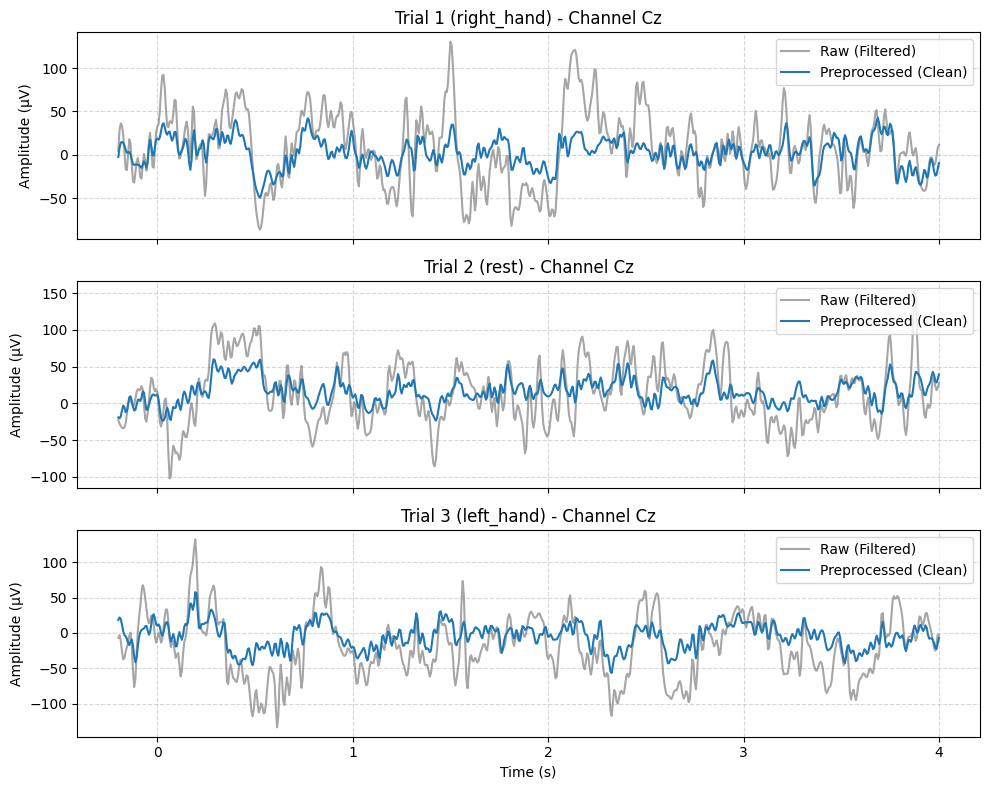

In [6]:
# Plot overlay of Cz channel for 3 epochs
cz_idx = epochs_raw.ch_names.index("Cz") if "Cz" in epochs_raw.ch_names else 0
times = epochs_raw.times

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for i in range(min(3, len(data_clean))):
    raw_sig = epochs_raw.get_data()[i, cz_idx, :] * 1e6  # uV
    clean_sig = data_clean[i, cz_idx, :] * 1e6            # uV
    
    axes[i].plot(times, raw_sig, label="Raw (Filtered)", color="gray", alpha=0.7)
    axes[i].plot(times, clean_sig, label="Preprocessed (Clean)", color="tab:blue", linewidth=1.5)
    axes[i].set_ylabel("Amplitude (µV)")
    axes[i].set_title(f"Trial {i+1} ({labels_clean[i]}) - Channel Cz")
    axes[i].legend(loc="upper right")
    axes[i].grid(True, linestyle="--", alpha=0.5)

axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()